   area  bedrooms  bathrooms  stories  age   price
0  3674         4          3        2   16  842100
1  1360         1          1        2   27  300000
2  1794         1          1        2   25  329000
3  1630         2          3        1    8  478500
4  1595         1          1        2   21  300000


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,497 (9.75 KB)

 Trainable params: 2,497 (9.75 KB)

 Non-trainable params: 0 (0.00 B)

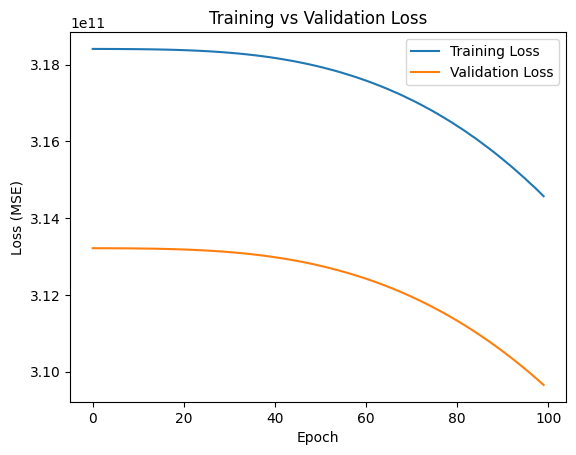

Test Mean Squared Error: 324489478144.0
Test Mean Absolute Error: 545467.5
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
   Actual Price  Predicted Price
0        369300      2206.412598
1        386500      3550.891602
2        497000      2089.876465
3        380500      1932.118408
4        813900      5298.809082
5        474100      2167.248535
6        766000      4043.838135
7        537600      3492.278320
8        765000      3921.733398
9        603800      4209.537109


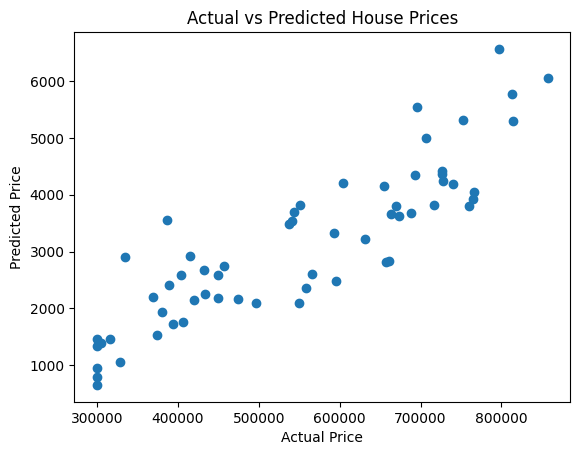

In [2]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Step 2: Load the dataset
data = pd.read_csv("house_prices.csv")
print(data.head())

# Step 3: Separate features (X) and target (y)
X = data.drop("price", axis=1)
y = data["price"]

# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Build the regression model using TensorFlow Keras
model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])
model.summary()

# Step 7: Compile the model
model.compile(optimizer="adam", loss="mse", metrics=["mae"])

# Step 8: Train the model
history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    verbose=0
)

# Step 9: Plot training loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

# Step 10: Evaluate the model on test data
test_loss, test_mae = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Test Mean Squared Error:", test_loss)
print("Test Mean Absolute Error:", test_mae)

# Step 11: Make predictions
predictions = model.predict(X_test_scaled).flatten()
comparison = pd.DataFrame({
    "Actual Price": y_test.values[:10],
    "Predicted Price": predictions[:10]
})
print(comparison)

# Step 12: Visualize actual vs predicted prices
plt.scatter(y_test, predictions)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.show()